# 01 — Behavioural Template Discovery

Discovers **behavioural templates**.

Each agent-day becomes a *document* of `(time slot, activity)` tokens, and LDA
is fit over those documents. Every topic is a template (a distribution over what
happens and when it happens in a dya), and every day of an gent is explained by a mixture over templates.

```
raw mobility data
      │
      ▼  src/data/*          load + harmonize activity labels
      ▼  src/features/*      encode each agent-day in one-hot encoding format.
      ▼  src/templates/lda   fit LDA (K topics = K templates)
      ▼  src/templates/*     diagnostics, figures, artifacts
```

All logic lives in `src/`; Every parameter comes from `configs/templates/default.yaml`.

**Template Discovery Steps:** build documents → choose K →
fit templates → check memberships.

### Prerequisites
| Dataset | Needs |
|---|---|
| NHTS | `data/raw/nhts_2017/trippub.csv` |
| NUMOSIM | nothing — downloaded from OSF on first run |
| Geolife | module 0 output: run `python -m src.data.geolife.split_dataset` first |

Equivalent CLI, if you don't need the narrative:
```bash
python -m src.templates.discover --dataset geolife --sweep
```

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

REPO_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(REPO_ROOT))

import pandas as pd

from src.features import build_documents
from src.templates import artifacts, diagnostics, discover, lda, plots
from src.utils.config import ROOT, load_cfg

cfg = load_cfg("configs/templates/default.yaml")
OUTPUT_DIR = ROOT / cfg["output_dir"]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

runs = {}   # dataset -> discovery result, collected for the comparison at the end
print(f"seed={cfg['seed']}  n_slots={cfg['n_slots']}  figures -> {cfg['output_dir']}")

seed=42  n_slots=96  figures -> output/template_discovery


---
## 1 — NHTS 2017

The US National Household Travel Survey: ~213k person-days, each surveyed for a
single travel day. Trips are expanded into a 96-slot timeline — dwell at the
destination, travel slots attributed to the origin, everything else Home — which
gives a `96 × n_activities` token vocabulary.

### 1a — Build documents

In [2]:
nhts_docs = build_documents("nhts", cfg)
print(f"{nhts_docs.n_docs:,} documents x {nhts_docs.X.shape[1]:,} tokens")
nhts_docs.labels

213,198 documents x 1,728 tokens


['Adultcare',
 'Childcare',
 'Education',
 'Errands',
 'Excercise',
 'Health',
 'Home',
 'Other',
 'Pickup_Dropoff',
 'Recreation',
 'Religious',
 'Restaurant',
 'Services',
 'Shopping',
 'Social',
 'Transportation',
 'Volunteer',
 'Work']

### 1b — Choose K

Refits LDA once per K over the configured range and plots the perplexity elbow.
This is the expensive step — skip it and keep the K already in the config if you
only want the templates. $K=6$ seems to be a reasonable choice that balances between behavioral diversity and personal characteristics.

Perplexity sweep over K=3..15
  K= 3    36.4s  perplexity=186.1
  K= 4    35.9s  perplexity=182.1
  K= 5    36.4s  perplexity=171.3
  K= 6    38.5s  perplexity=167.8
  K= 7    37.1s  perplexity=166.9
  K= 8    37.8s  perplexity=166.8
  K= 9    38.2s  perplexity=163.1
  K=10    38.3s  perplexity=160.9
  K=11    39.0s  perplexity=158.3
  K=12    38.3s  perplexity=158.5
  K=13    39.6s  perplexity=157.5
  K=14    38.7s  perplexity=155.2
  K=15    39.6s  perplexity=156.0


,k,perplexity
0,3,186.121924
1,4,182.109768
2,5,171.310094
3,6,167.846128
4,7,166.905003
5,8,166.809592
6,9,163.132765
7,10,160.888099
8,11,158.311371
9,12,158.486123


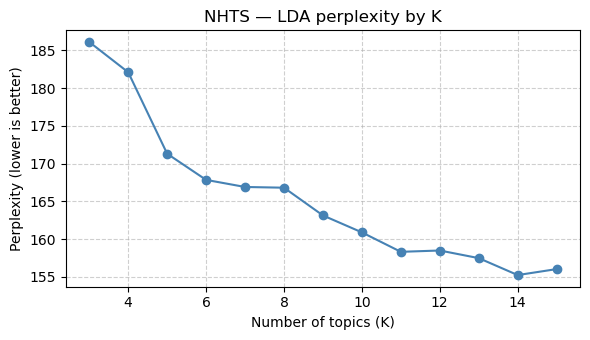

In [3]:
nhts_sweep = discover.run_sweep(nhts_docs, cfg, OUTPUT_DIR)
nhts_sweep

### 1b — Fit templates at the chosen K

`discover` fits the model, saves the artifact to `artifacts/templates/`, and
writes the template + membership figures.

nhts: 213,198 documents  18 activities  96 slots
  K= 6    37.4s  perplexity=167.8
  frac_pure=0.476  mean_max_prob=0.832  mean_entropy=0.408  frac_entropy_log_k=0.228
  saved artifacts/templates/nhts_lda.pkl


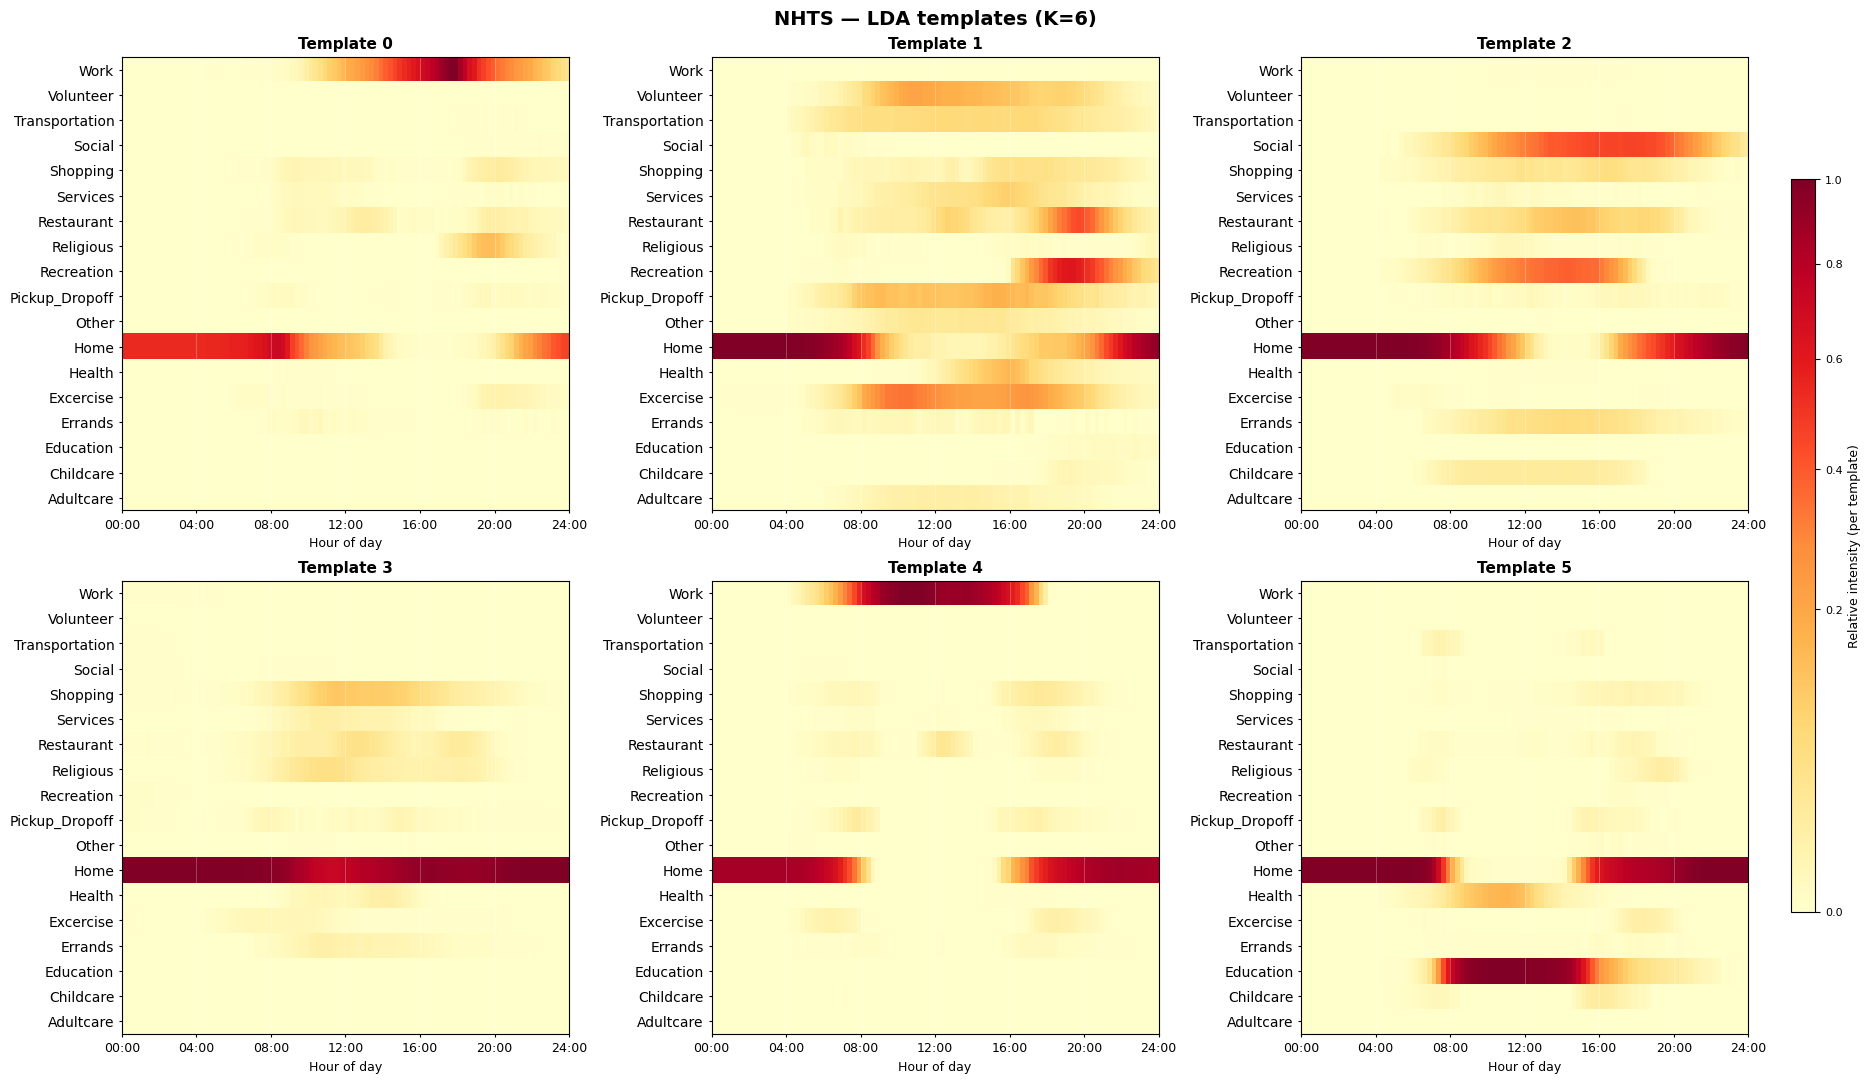

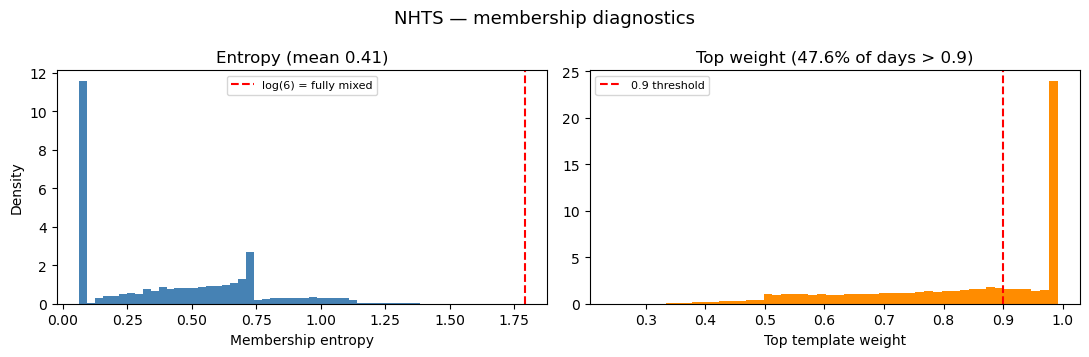

In [4]:
runs["nhts"] = discover.discover("nhts", cfg, documents=nhts_docs)

---
## 2 — NUMOSIM

Synthetic multi-year urban mobility. A POI carries a *set* of activity types, so
the vocabulary is the set of distinct activity **bundles** rather than single
activities. The parquet files download from OSF on first run.

LDA is fit on a subsample (`datasets.numosim.subsample`) to keep the fit
tractable; every document is still encoded through the fitted model.

### 2a — Build documents

In [5]:
numosim_docs = build_documents("numosim", cfg)
print(f"{numosim_docs.n_docs:,} documents x {numosim_docs.n_acts} bundles")
numosim_docs.labels[:10]

NUMOSIM: all 2 files already in data/raw/numosim
5,785,961 documents x 28 bundles


['EatOut',
 'Excercise',
 'Religious',
 'SomethingElse',
 'Work',
 'BuyGoods+Work',
 'DropOff+Recreation',
 'DropOff+SomethingElse',
 'DropOff+Work',
 'EatOut+Work']

### 2b — Choose K

$K=6$ seems to be a reasonable value for our templates.

  fitting on a 200,000-document subsample of 5,785,961
Perplexity sweep over K=3..15
  K= 3    31.8s  perplexity=231.5
  K= 4    34.6s  perplexity=214.8
  K= 5    31.4s  perplexity=202.7
  K= 6    35.6s  perplexity=194.8
  K= 7    35.9s  perplexity=186.0
  K= 8    34.5s  perplexity=183.7
  K= 9    34.9s  perplexity=180.2
  K=10    38.0s  perplexity=175.4
  K=11    36.4s  perplexity=169.4
  K=12    38.6s  perplexity=170.9
  K=13    38.9s  perplexity=165.3
  K=14    39.1s  perplexity=163.2
  K=15    40.3s  perplexity=163.5


,k,perplexity
0,3,231.484553
1,4,214.763553
2,5,202.652925
3,6,194.770555
4,7,186.047021
5,8,183.662361
6,9,180.211139
7,10,175.444128
8,11,169.366222
9,12,170.870551


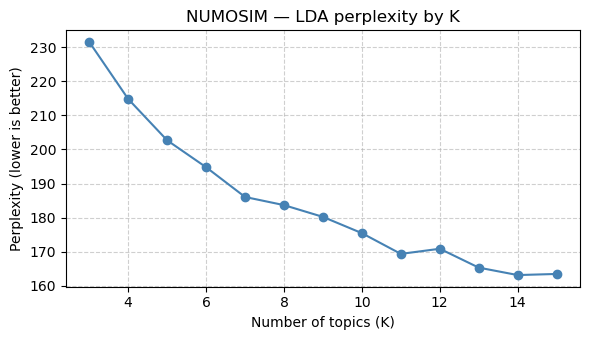

In [6]:
numosim_sweep = discover.run_sweep(numosim_docs, cfg, OUTPUT_DIR)
numosim_sweep

### 2c — Fit templates at the chosen K

numosim: 5,785,961 documents  28 activities  96 slots
  fitting on a 200,000-document subsample of 5,785,961
  K= 6    35.3s  perplexity=194.8
  frac_pure=0.440  mean_max_prob=0.817  mean_entropy=0.446  frac_entropy_log_k=0.249
  saved artifacts/templates/numosim_lda.pkl


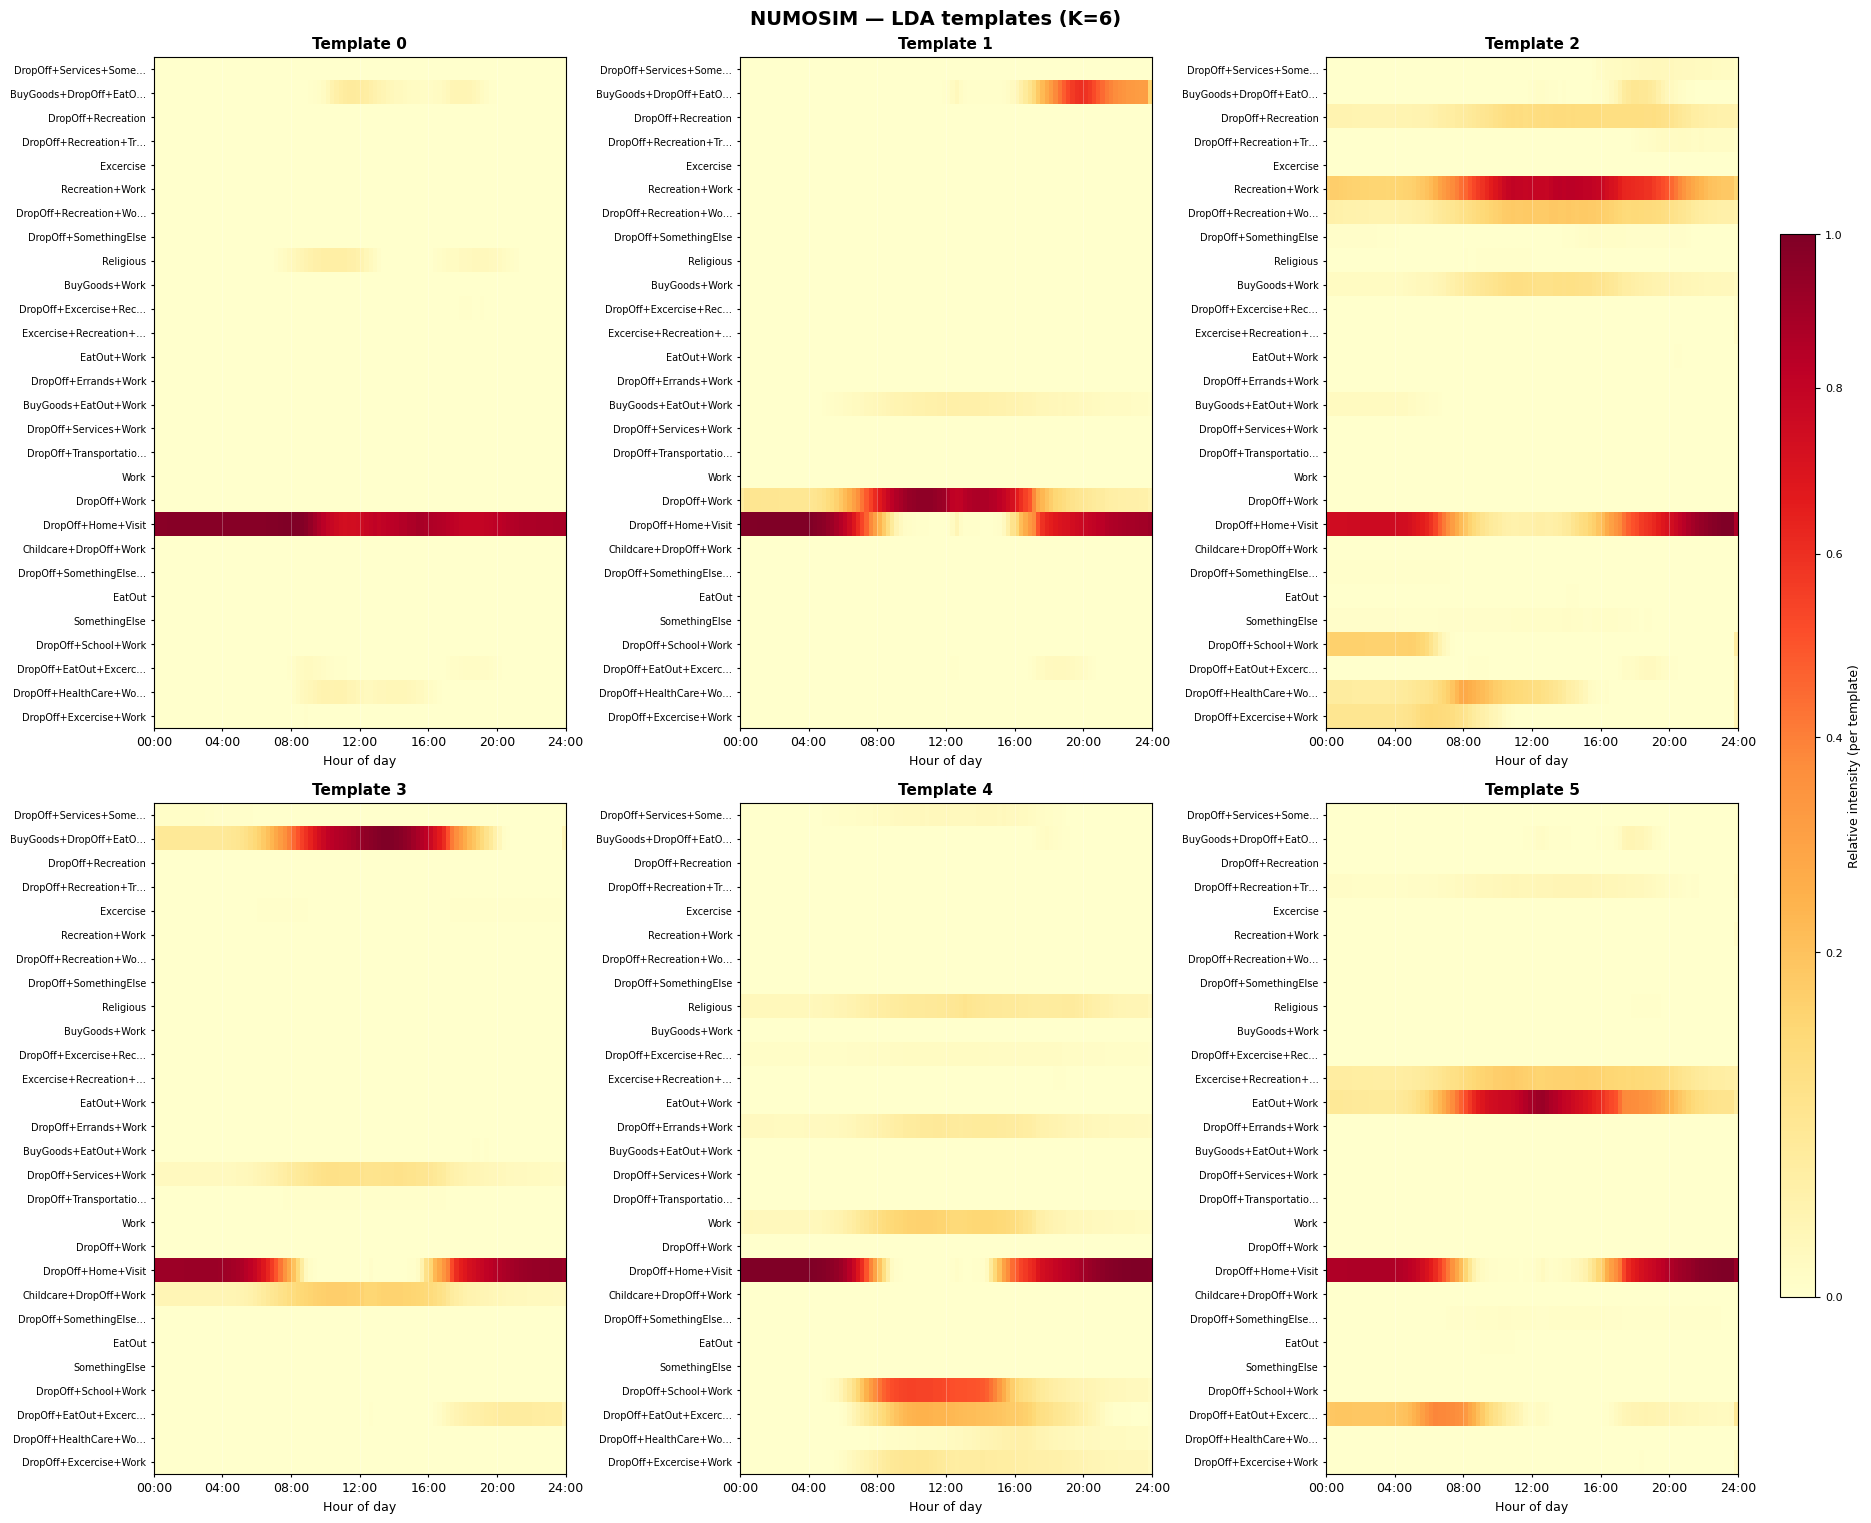

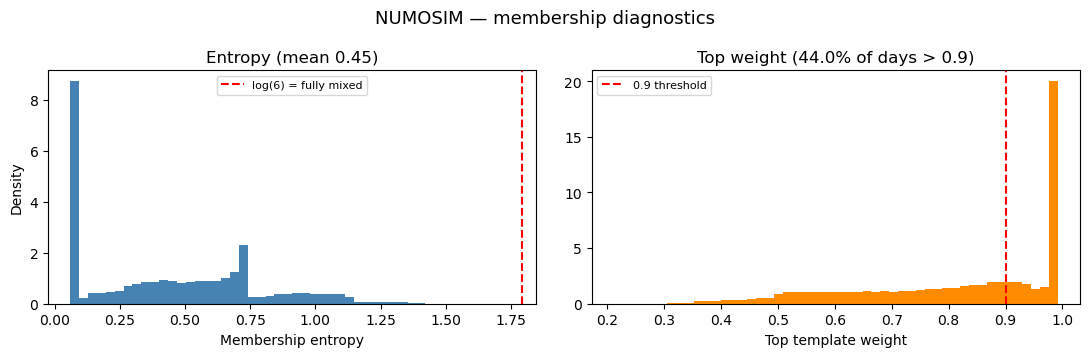

In [7]:
runs["numosim"] = discover.discover("numosim", cfg, documents=numosim_docs)

---
## 3 — Geolife

Real GPS trajectories, labelled by module 0 (`src/data/geolife/`) into NHTS
activity categories. Smaller and sparser than the other two: ~70 agents over
three years. Only the **train** split is used, so templates never see val/test.

Stays that cross midnight are split across both days; slots with no stay stay Home.

### 3a — Build documents

In [8]:
geolife_docs = build_documents("geolife", cfg)
print(f"{geolife_docs.n_docs:,} documents x {geolife_docs.n_acts} activities")
geolife_docs.index.head()

5,700 documents x 17 activities


,agent_id,date,n_staypoints
0,0,2008-10-23,2
1,0,2008-10-28,2
2,0,2008-11-04,1
3,0,2008-11-10,1
4,0,2008-11-11,1


### 3b — Choose K

Perplexity sweep over K=3..15
  K= 3    23.6s  perplexity=271.2
  K= 4    23.8s  perplexity=247.9
  K= 5    23.9s  perplexity=244.3
  K= 6    24.5s  perplexity=230.9
  K= 7    24.2s  perplexity=225.2
  K= 8    25.7s  perplexity=217.1
  K= 9    24.7s  perplexity=212.9
  K=10    25.7s  perplexity=211.1
  K=11    25.8s  perplexity=208.0
  K=12    25.3s  perplexity=205.2
  K=13    25.8s  perplexity=203.3
  K=14    25.8s  perplexity=202.9
  K=15    26.8s  perplexity=198.7


,k,perplexity
0,3,271.187047
1,4,247.939659
2,5,244.291142
3,6,230.870181
4,7,225.191560
5,8,217.058586
6,9,212.910570
7,10,211.137307
8,11,208.048364
9,12,205.158528


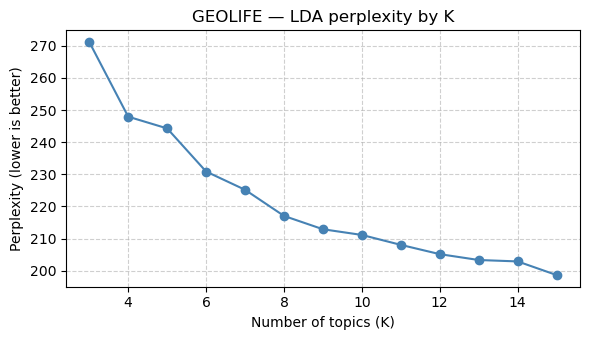

In [9]:
geolife_sweep = discover.run_sweep(geolife_docs, cfg, OUTPUT_DIR)
geolife_sweep

### 3c — Fit templates at the chosen K

geolife: 5,700 documents  17 activities  96 slots
  K= 6    24.3s  perplexity=230.9
  frac_pure=0.261  mean_max_prob=0.722  mean_entropy=0.649  frac_entropy_log_k=0.362
  saved artifacts/templates/geolife_lda.pkl


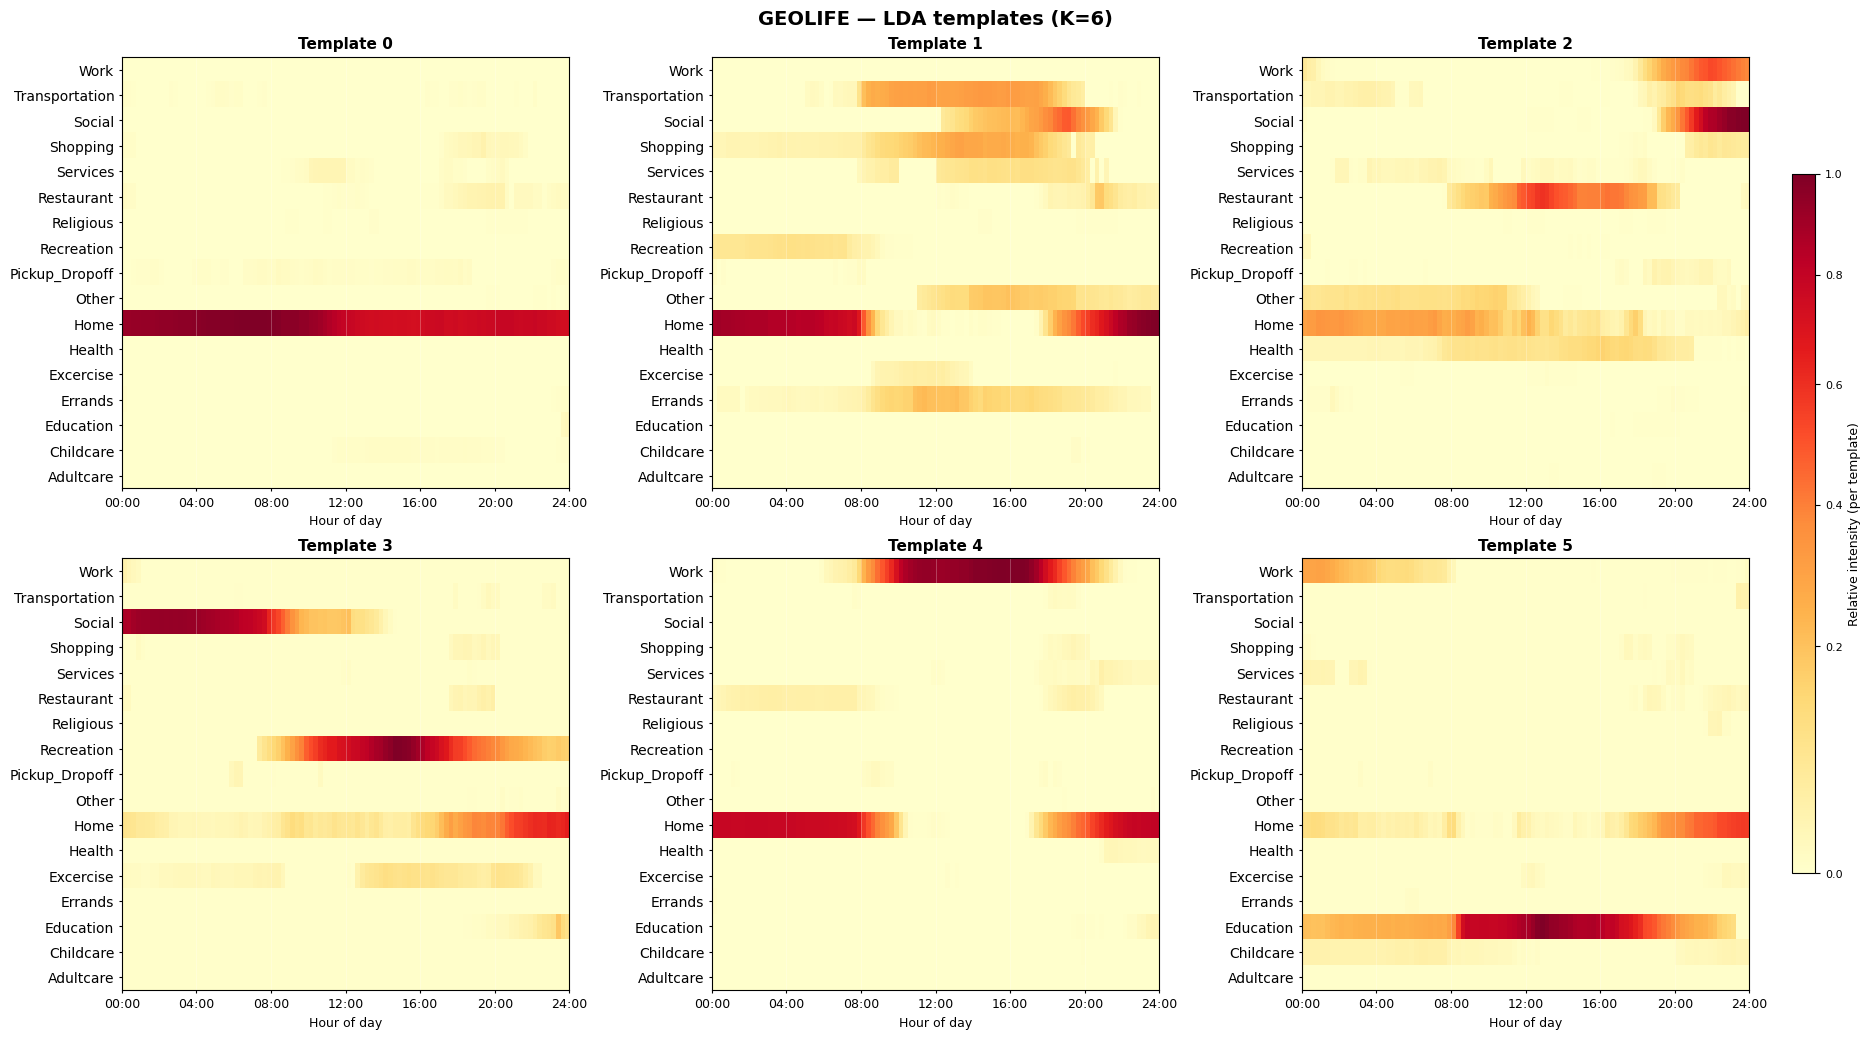

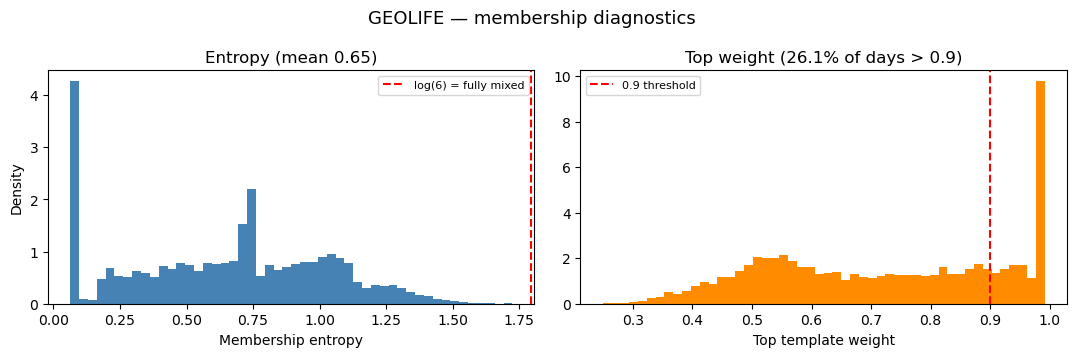

In [10]:
runs["geolife"] = discover.discover("geolife", cfg, documents=geolife_docs)

---
## 4 — Cross-dataset comparison

### 4a — Template shapes

The same activity keeps the same colour in every panel, so templates can be
compared across datasets. Each panel shows the few activities that carry the
template.

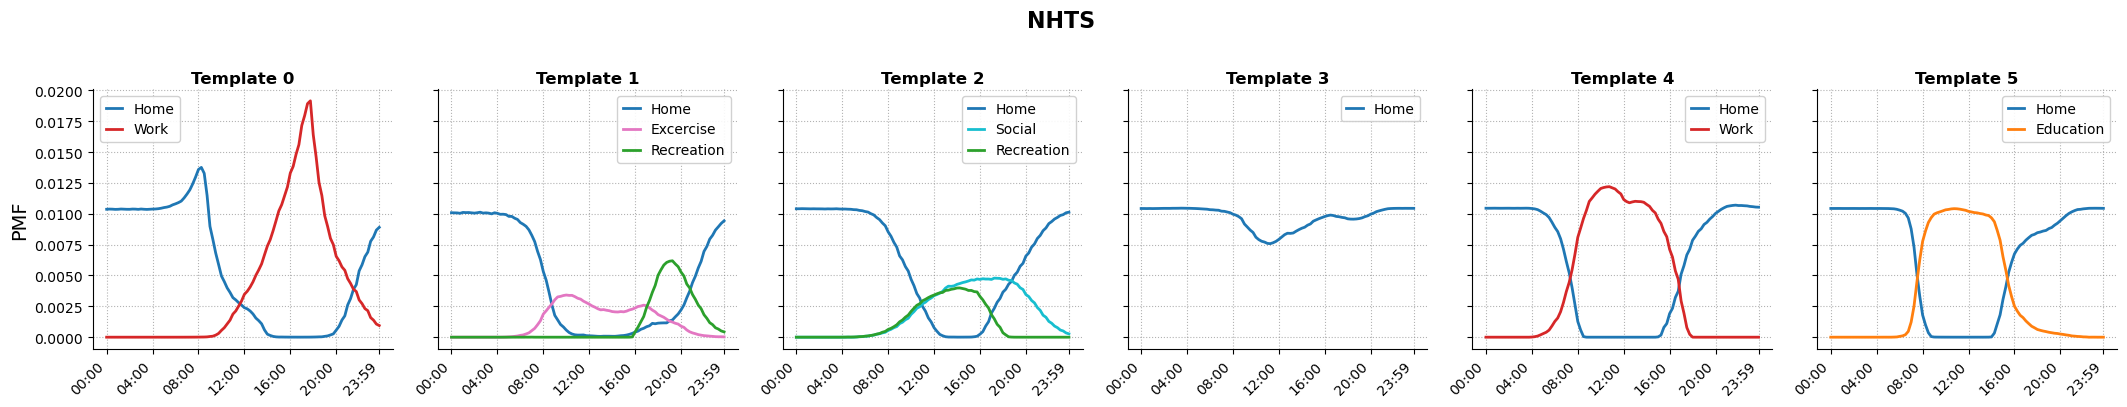

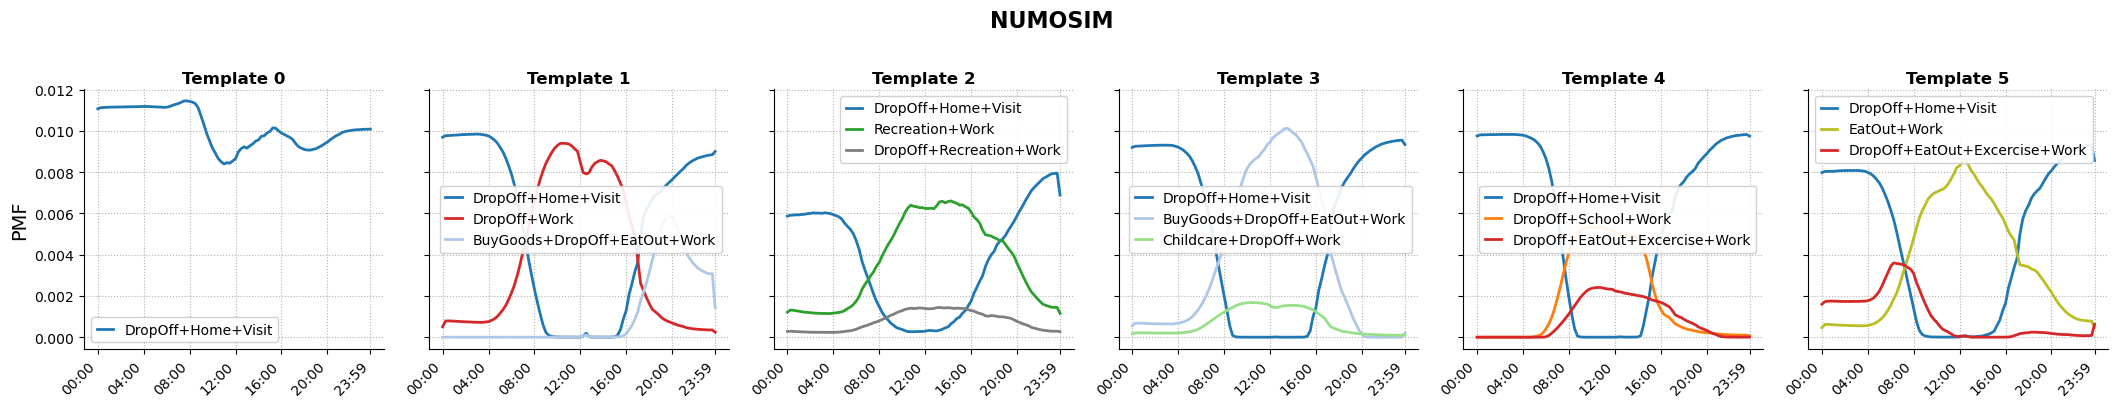

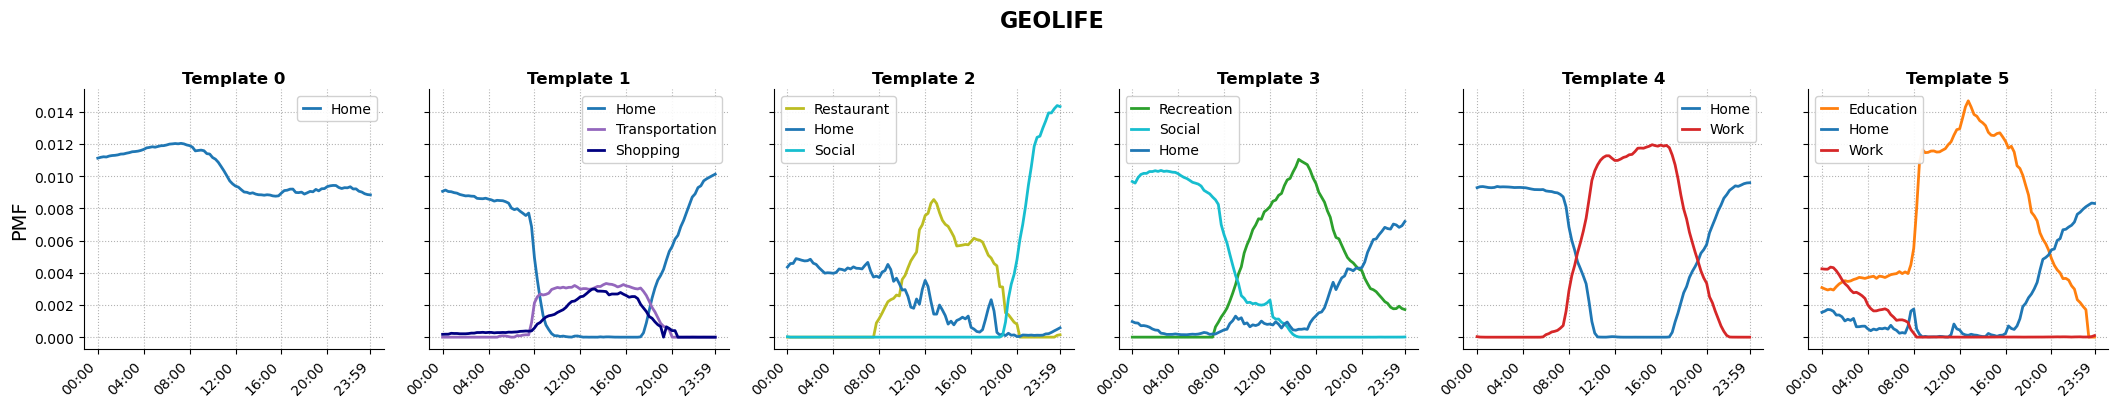

In [11]:
colors = plots.activity_colors([run["documents"].labels for run in runs.values()])

for name, run in runs.items():
    plots.plot_topic_sparklines(
        run["phi"],
        run["documents"],
        title=name.upper(),
        colors=colors,
        output_path=OUTPUT_DIR / f"{name}_sparklines.png",
    )

### 4b — Reusing the templates

Each run is pickled to `artifacts/templates/<dataset>_lda.pkl` with the fitted
model, the per-day mixtures, the agent-day index, and the vocabulary the columns
assume. Downstream modules should load it rather than refitting.

In [12]:
dataset = list(runs)[-1]   # whichever dataset section you ran last
saved = artifacts.load(ROOT / cfg["artifacts_dir"], dataset)
print(dataset, {k: type(v).__name__ for k, v in saved.items()})
print("K:", saved["k"], " theta:", saved["theta"].shape, " vocab:", saved["vocab"]["n_acts"])

geolife {'dataset': 'str', 'k': 'int', 'lda': 'LatentDirichletAllocation', 'theta': 'ndarray', 'index': 'DataFrame', 'vocab': 'dict'}
K: 6  theta: (5700, 6)  vocab: 17
